# 04-3. 결빙 분류: 검증 지점 평가와 저장

04(결빙 발생 분류)의 3~5장. 04-1에서 정한 최종 모델과 임계값으로 검증 지점 3곳의 10분 단위 결빙을 예측하고,
일별 F1·Precision·Recall과 평가기간 평균을 낸다.

04 구성: 04-1 Ice 라벨·후보 모델·교차검증(0~1장) · 04-2 고전 ML 비교(2장) · **04-3 검증 지점 평가·저장(3~5장)**

- 입력: 02-2의 지점 변수, 03-3의 추정 노면온도, 04-1의 후보 모델·설정 (`icing_models.joblib`, `icing_cv.json`)
- 출력: 검증 지점 성능지표·10분 단위 예측 (`data/results/icing_scores.csv`, `icing_daily_scores.csv`,
  `icing_10min_scores.csv`, `icing_holdout_10min.csv`), 그림 (`figures/icing_holdout_12410.png`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import warnings

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
SEED = 42

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
sf = sf.merge(pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
sf["rst_dpd"] = sf["rst_est"] - sf["td"]  # 추정 노면온도 - 이슬점 (04-1과 같음)
sf["date"] = sf["time"].dt.normalize()
cv = json.load(open(config.PROCESSED_DIR / "icing_cv.json", encoding="utf-8"))  # 04-1에서 정한 설정
CLS_FEATURES, CANDIDATES, thresholds, FINAL = cv["features"], cv["candidates"], cv["thresholds"], cv["final"]
THRESHOLD = thresholds[FINAL]
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
holdout = sf[sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
full_models = joblib.load(config.PROCESSED_DIR / "icing_models.joblib")  # 학습 지점 14곳 전체로 학습한 후보 모델
model = full_models[FINAL]
print(f"최종 모델: {FINAL} (임계값 {THRESHOLD:.3f}), 검증 지점 {holdout.shape}")

최종 모델: LightGBM(결빙관련 라벨) (임계값 0.848), 검증 지점 (103680, 50)


결빙 판정 함수 (04-1의 1장과 같은 정의): 학습 모델의 확률, 규칙 기반·Bonanno 결빙 기준·서리 조건

In [4]:
def predict_icing(model, df, features=CLS_FEATURES):
    """10분 단위 결빙 확률."""
    return model.predict_proba(df[features])[:, 1]


def rule_based(df):
    return ((df["rst_est"] <= 0) & (df["rh"] >= 80) & (df["nbr_wet"] >= 0.5)).to_numpy()


def bonanno_rule(df):
    """Bonanno et al.(2010): 노면에 수분이 있을 때 강수 중이면 노면 < 1°C, 강수가 없으면 노면 < 0°C에서 결빙."""
    raining = df["rain"] >= 0.5
    moist = raining | (df["rain_hrs12h"] > 0) | (df["snow"] > 0) | (df["rst_dpd"] <= 0)
    return (moist & np.where(raining, df["rst_est"] < 1, df["rst_est"] < 0)).to_numpy()


def frost_rule(df):
    """Jang(2024)의 서리 조건: 노면온도 ≤ 0°C 이고 노면온도 ≤ 이슬점."""
    return ((df["rst_est"] <= 0) & (df["rst_dpd"] <= 0)).to_numpy()


RULES = {"규칙 기반": rule_based, "Bonanno 결빙 기준": bonanno_rule, "서리 조건(Jang)": frost_rule}

## 3. 검증 지점 10분 단위 예측

In [5]:
holdout["prob"] = predict_icing(model, holdout)
holdout["pred"] = (holdout["prob"] >= THRESHOLD).astype(int)
RULE_COLS = {"규칙 기반": "pred_rule", "Bonanno 결빙 기준": "pred_bonanno", "서리 조건(Jang)": "pred_frost"}
for name, col in RULE_COLS.items():
    holdout[col] = RULES[name](holdout).astype(int)
OTHER_COLS = {}
for i, name in enumerate(n for n in CANDIDATES if n != FINAL):
    m = full_models[name]
    OTHER_COLS[name] = f"pred_other{i}"
    holdout[OTHER_COLS[name]] = (predict_icing(m, holdout) >= thresholds[name]).astype(int)
holdout.groupby("stn").agg(Ice관측=("ice", "sum"), Ice예측=("pred", "sum"), 최대확률=("prob", "max")).join(
    stations["name"])

,Ice관측,Ice예측,최대확률,name
stn,,,,
12410,64.0,157,0.944397,부곡교(도)
23402,0.0,147,0.958229,해전(도)
33411,0.0,265,0.970610,삼봉(도)


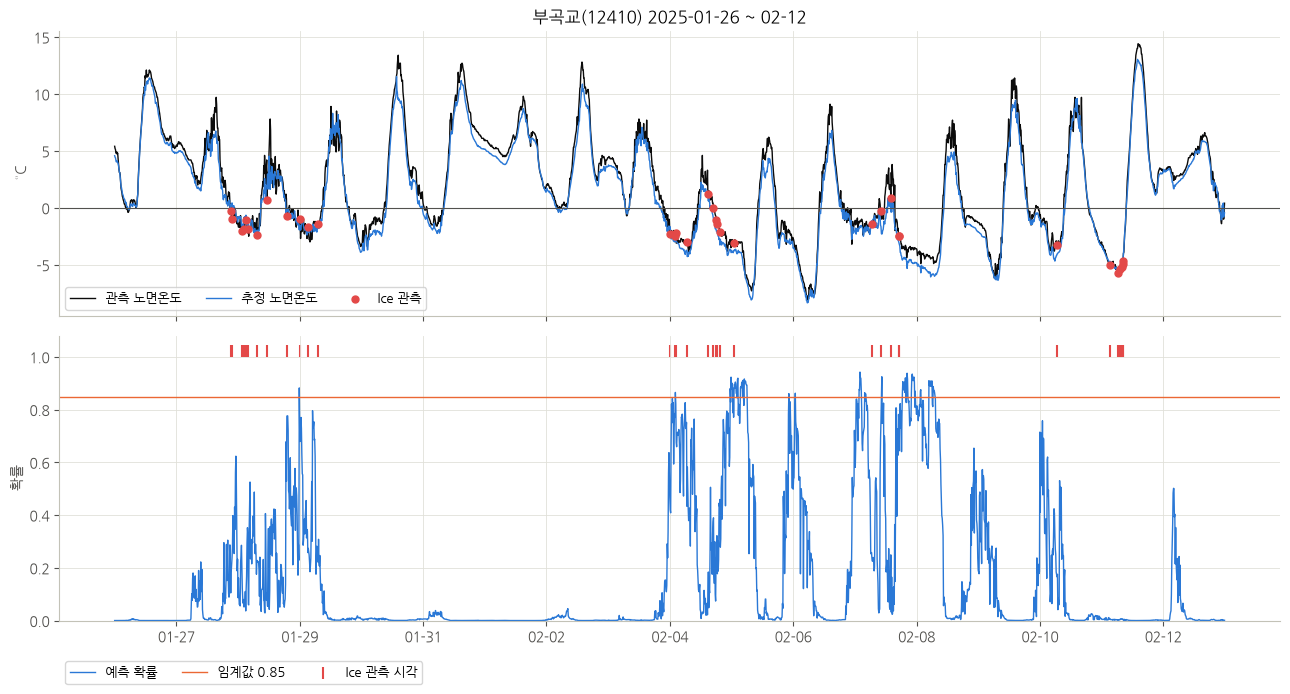

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
g = holdout[holdout["stn"] == 12410].set_index("time").loc["2025-01-26":"2025-02-12"]
axes[0].plot(g.index, g["rst"], color="#0b0b0b", linewidth=1, label="관측 노면온도")
axes[0].plot(g.index, g["rst_est"], color="#2a78d6", linewidth=1, label="추정 노면온도")
ice = g.index[g["ice"] == 1]
axes[0].scatter(ice, g.loc[ice, "rst"], color="#e34948", s=25, zorder=5, label="Ice 관측")
axes[0].axhline(0, color="#52514e", linewidth=0.8)
axes[0].set_ylabel("°C")
axes[0].legend(ncol=3, fontsize=9)
axes[1].plot(g.index, g["prob"], color="#2a78d6", linewidth=1, label="예측 확률")
axes[1].axhline(THRESHOLD, color="#eb6834", linewidth=1, label=f"임계값 {THRESHOLD:.2f}")
axes[1].scatter(ice, np.full(len(ice), 1.02), color="#e34948", marker="|", s=80, label="Ice 관측 시각")
axes[1].set_ylabel("확률")
axes[1].set_ylim(0, 1.08)
axes[1].legend(ncol=3, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.12))
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[0].set_title("부곡교(12410) 2025-01-26 ~ 02-12")
plt.tight_layout()
fig.savefig(config.FIGURE_DIR / "icing_holdout_12410.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. 일별 성능지표 및 평균

일별 TP·FP·FN으로 F1·Precision·Recall을 구하고 평가기간 평균을 낸다 (지점별, 세 지점 평균).
실제·예측 모두 결빙이 없는 날(TP+FP+FN=0)을 **제외**한 결과와 **1점**으로 본 결과를 함께 제시한다.

평가 함수: 일별 TP·FP·FN과 지표(04-1의 0장과 같은 정의), 지점별 평가기간 평균

In [7]:
def daily_icing_scores(df, empty_day="skip"):
    """한 지점(또는 여러 지점)의 일별 TP, FP, FN, Precision, Recall, F1.

    Args:
        df: stn, time, y_true(0/1), y_pred(0/1) 컬럼을 가진 10분 단위 DataFrame. y_true가 NaN인 시각은 뺀다.
        empty_day: 실제·예측 모두 결빙이 없는 날(TP+FP+FN=0)의 처리
            "skip" - 평균에서 뺀다 (기본)
            "one"  - 완벽히 맞힌 날로 보고 1점을 준다
    분모가 0인 지표(예: 예측이 없는 날의 Precision)는 0으로 둔다.
    """
    d = df.dropna(subset=["y_true"]).copy()
    d["date"] = d["time"].dt.normalize()
    y, p = d["y_true"].astype(int), d["y_pred"].astype(int)
    d["TP"], d["FP"], d["FN"] = y & p, (1 - y) & p, y & (1 - p)
    day = d.groupby(["stn", "date"])[["TP", "FP", "FN"]].sum()
    tp, fp, fn = day["TP"], day["FP"], day["FN"]
    day["Precision"] = np.where(tp + fp > 0, tp / (tp + fp).replace(0, 1), 0.0)
    day["Recall"] = np.where(tp + fn > 0, tp / (tp + fn).replace(0, 1), 0.0)
    day["F1"] = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn).replace(0, 1), 0.0)
    empty = (tp + fp + fn) == 0
    day.loc[empty, ["Precision", "Recall", "F1"]] = np.nan if empty_day == "skip" else 1.0
    day["evaluated"] = ~empty if empty_day == "skip" else True
    return day.reset_index()


def summarize_holdout(daily, names=None):
    """지점별 평가기간 평균과 지점 평균 행."""
    g = daily.assign(obs_day=(daily["TP"] + daily["FN"]) > 0, fp_day=daily["FP"] > 0).groupby("stn")
    out = pd.DataFrame({
        "평가일수": g["evaluated"].sum(), "결빙관측일수": g["obs_day"].sum(), "오탐일수": g["fp_day"].sum(),
        "F1": g["F1"].mean(), "Precision": g["Precision"].mean(), "Recall": g["Recall"].mean(),
    })
    if names is not None:
        out.insert(0, "지점명", names.reindex(out.index))
    mean = out.mean(numeric_only=True).to_frame().T
    mean.index = ["지점 평균"]
    if names is not None:
        mean.insert(0, "지점명", f"{len(out)}개 지점 평균")
    return pd.concat([out, mean])

In [8]:
def holdout_daily(pred_col, empty_day):
    df = holdout[["stn", "time"]].assign(y_true=holdout["ice"], y_pred=holdout[pred_col])
    return daily_icing_scores(df, empty_day)


names = stations["name"]
results = {}
for label, col in [(FINAL, "pred"), *OTHER_COLS.items(), *RULE_COLS.items()]:
    for empty_day, desc in [("skip", "빈 날 제외"), ("one", "빈 날 1점")]:
        results[(label, desc)] = summarize_holdout(holdout_daily(col, empty_day), names)

final_skip = results[(FINAL, "빈 날 제외")]
final_skip.round(3)

,지점명,평가일수,결빙관측일수,오탐일수,F1,Precision,Recall
12410,부곡교(도),27.0,19.000,15.0,0.029,0.019,0.068
23402,해전(도),10.0,0.000,10.0,0.000,0.000,0.000
33411,삼봉(도),14.0,0.000,14.0,0.000,0.000,0.000
지점 평균,3개 지점 평균,17.0,6.333,13.0,0.010,0.006,0.023


In [9]:
results[(FINAL, "빈 날 1점")].round(3)

,지점명,평가일수,결빙관측일수,오탐일수,F1,Precision,Recall
12410,부곡교(도),240.0,19.000,15.0,0.891,0.890,0.895
23402,해전(도),240.0,0.000,10.0,0.958,0.958,0.958
33411,삼봉(도),240.0,0.000,14.0,0.942,0.942,0.942
지점 평균,3개 지점 평균,240.0,6.333,13.0,0.930,0.930,0.932


- 삼봉(33411)·해전(23402)은 평가기간 내내 Ice가 없다. 빈 날 제외 방식에서는 오탐한 날만 평가일(F1=0)이 되고,
  오탐이 없으면 평가일이 0일이라 값이 없다(NaN). 세 지점 평균은 값이 있는 지점만으로 낸다.
- 빈 날 1점 방식에서는 두 지점이 거의 1에 가깝게 나온다.

In [10]:
compare = pd.DataFrame({
    f"{label} / {desc}": r.loc["지점 평균", ["F1", "Precision", "Recall", "오탐일수"]]
    for (label, desc), r in results.items()
}).T
compare.round(3)

,F1,Precision,Recall,오탐일수
LightGBM(결빙관련 라벨) / 빈 날 제외,0.010,0.006,0.023,13.000
LightGBM(결빙관련 라벨) / 빈 날 1점,0.930,0.930,0.932,13.000
LightGBM(Ice 라벨) / 빈 날 제외,0.014,0.034,0.009,11.667
LightGBM(Ice 라벨) / 빈 날 1점,0.935,0.936,0.934,11.667
로지스틱 회귀(결빙관련 라벨) / 빈 날 제외,0.006,0.004,0.040,18.667
로지스틱 회귀(결빙관련 라벨) / 빈 날 1점,0.913,0.913,0.918,18.667
규칙 기반 / 빈 날 제외,0.004,0.003,0.021,89.667
규칙 기반 / 빈 날 1점,0.624,0.623,0.629,89.667
Bonanno 결빙 기준 / 빈 날 제외,0.007,0.004,0.060,84.333
Bonanno 결빙 기준 / 빈 날 1점,0.651,0.650,0.667,84.333


최종 모델(LightGBM, 결빙관련 라벨)의 검증 지점 일별 F1(빈 날 제외)은 0.010이다. 해석용 로지스틱 회귀는 0.006이다.
로지스틱은 결빙 판정이 LightGBM의 약 두 배라 오탐일이 많다 (세 지점 평균 13일 vs 19일). 대신 재현율은 높다 (0.023 vs 0.040).
교차검증에서는 순위가 반대였고 (0.026 vs 0.032), 검증 지점에서 Ice가 관측된 곳은 부곡교 한 곳(19일)뿐이라
이 차이도 우연과 구분되지 않는다. 이 결과를 최종 모델 선택에 참고했다는 점(1절)을 밝혀 둔다.

검증 지점에서도 이론 기준은 학습 모델보다 낮다. Bonanno 결빙 기준은 세 지점 평균 84일을 오탐하고, 서리 조건은 Ice를 하나도 맞히지 못한다.
이론 기준은 결빙이 **가능한** 조건을 알려 줄 뿐이다. 그래서 05에서는 같은 구조(저온 + 수분 공급)의 결빙 가능 조건을 판정 규칙이 아니라
구간별 "결빙 가능 시간"(위험도의 기상 요인)으로 쓴다.

10분 단위 전체 시각을 한꺼번에 본 혼동행렬과 지표 (지점별)

In [11]:
def tenmin_scores(df, pred_col):
    rows = []
    for stn, g in df.dropna(subset=["ice"]).groupby("stn"):
        y, p = g["ice"].astype(int), g[pred_col].astype(int)
        tp, fp, fn = int((y & p).sum()), int(((1 - y) & p).sum()), int((y & (1 - p)).sum())
        rows.append({"stn": stn, "지점명": names[stn], "TP": tp, "FP": fp, "FN": fn, "TN": int(len(g) - tp - fp - fn),
                     "Precision": tp / (tp + fp) if tp + fp else 0.0, "Recall": tp / (tp + fn) if tp + fn else 0.0,
                     "F1": 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan})
    return pd.DataFrame(rows).set_index("stn")


tenmin = tenmin_scores(holdout, "pred")
tenmin.round(4)

,지점명,TP,FP,FN,TN,Precision,Recall,F1
stn,,,,,,,,
12410,부곡교(도),6,151,58,34340,0.0382,0.0938,0.0543
23402,해전(도),0,147,0,34375,0.0000,0.0000,0.0000
33411,삼봉(도),0,265,0,34284,0.0000,0.0000,0.0000


## 5. 결과 저장
성능지표 CSV, 10분 단위 예측 결과 (config.RESULT_DIR). 최종 모델 파일은 04-1에서 저장한다.

In [12]:
out = []
for (label, desc), r in results.items():
    out.append(r.reset_index(names="stn").assign(방법=label, 빈날처리=desc))
pd.concat(out).round(4).to_csv(config.RESULT_DIR / "icing_scores.csv", index=False, encoding="utf-8-sig")
holdout_daily("pred", "skip").assign(지점명=lambda d: d["stn"].map(names)).round(4).to_csv(
    config.RESULT_DIR / "icing_daily_scores.csv", index=False, encoding="utf-8-sig")
tenmin.round(4).to_csv(config.RESULT_DIR / "icing_10min_scores.csv", encoding="utf-8-sig")
(holdout[["stn", "time", "ice", "prob", "pred"]].rename(columns={"ice": "ice_obs", "pred": "ice_pred"})
 .assign(prob=lambda d: d["prob"].round(4))
 .to_csv(config.RESULT_DIR / "icing_holdout_10min.csv", index=False, encoding="utf-8-sig"))
print("저장 완료")

저장 완료
